# Prediksi Customer Churn dalam Industri Telekomunikasi
**Assignment 1: Ready-to-Use Data**  
*Mata Kuliah: Applied Artificial Intelligence — STMIK Tazkia*

---

## 1. Problem and Data Description

### 1.1 Business Problem & Prediction Goal
Tingginya angka pelanggan yang berhenti berlangganan (*Customer Churn*) berdampak langsung terhadap hilangnya pendapatan berulang bulanan (*Monthly Recurring Revenue* / MRR). Karena biaya akuisisi pelanggan baru 5–25x lebih mahal daripada retensi, tujuan proyek ini adalah:
> *"Membangun model Machine Learning untuk memprediksi pelanggan berisiko **churn** di masa mendatang, sehingga perusahaan dapat memberikan intervensi retensi (diskon kontrak atau perbaikan teknis) lebih awal."*

* **Sumber Data:** Kaggle — [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM Cognos Analytics).
* **Target Variabel:** `Churn` (1 = Churn, 0 = Stay).


In [1]:
# 1.2 Ringkasan Metadata Dataset (Tanpa Dump Teks Panjang)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style visualisasi bersih
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except Exception:
    plt.style.use('ggplot')

# Membaca dataset
file_name = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
url = 'https://raw.githubusercontent.com/Waleeed/Telco-Customer-Churn/master/WA_Fn-UseC_-Telco-Customer-Churn.csv'

if not os.path.exists(file_name):
    try:
        df = pd.read_csv(url)
        df.to_csv(file_name, index=False)
    except Exception:
        alt_url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
        df = pd.read_csv(alt_url)
        df.to_csv(file_name, index=False)
else:
    df = pd.read_csv(file_name)

# Ringkasan Eksekutif Dataset (4 Poin Utama)
print("=== RINGKASAN DATASET AWAL ===")
print(f"• Total Baris (Pelanggan) : {df.shape[0]:,} baris")
print(f"• Total Kolom (Fitur)     : {df.shape[1]} kolom")
print(f"• Komposisi Tipe Data     : {df.dtypes.value_counts().to_dict()}")
print(f"• Jumlah Data Duplikat    : {df.duplicated().sum()} baris")

# Cuplikan 5 Kolom Kunci Saja (Biar tidak melebar ke samping)
print("\n=== CUPLIKAN 5 KOLOM KUNCI ===")
df[['tenure', 'Contract', 'InternetService', 'MonthlyCharges', 'Churn']].head(3)


=== RINGKASAN DATASET AWAL ===
• Total Baris (Pelanggan) : 7,043 baris
• Total Kolom (Fitur)     : 21 kolom
• Komposisi Tipe Data     : {dtype('O'): 18, dtype('int64'): 2, dtype('float64'): 1}
• Jumlah Data Duplikat    : 0 baris

=== CUPLIKAN 5 KOLOM KUNCI ===


,tenure,Contract,InternetService,MonthlyCharges,Churn
0,1,Month-to-month,DSL,29.85,No
1,34,One year,DSL,56.95,No
2,2,Month-to-month,DSL,53.85,Yes


## 2. Exploratory Data Analysis (EDA)
Pemeriksaan data mentah untuk menemukan pola bisnis, proporsi target, dan anomali sebelum dibersihkan.


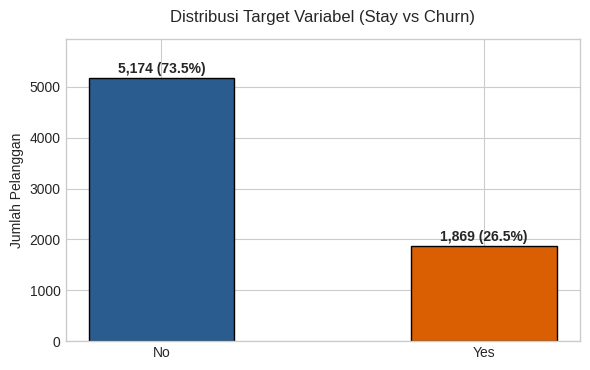

In [2]:
# 2.1 Distribusi Target Variabel (Churn)
churn_counts = df['Churn'].value_counts()
colors = ['#2b5c8f', '#d95f02']

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(churn_counts.index, churn_counts.values, color=colors, width=0.45, edgecolor='black')

total = len(df)
for bar in bars:
    yval = bar.get_height()
    pct = (yval / total) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 100, f"{yval:,} ({pct:.1f}%)", ha='center', fontweight='bold')

ax.set_title('Distribusi Target Variabel (Stay vs Churn)', pad=12)
ax.set_ylabel('Jumlah Pelanggan')
ax.set_ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
plt.show()


**Insight 1:**  
73,5% pelanggan bertahan (*Stay*) dan 26,5% churn. Terdapat kondisi *moderate class imbalance*, sehingga metrik evaluasi model wajib menggunakan *F1-score / Recall*, bukan akurasi saja.


In [3]:
# 2.2 Temuan Anomali Missing Values pada TotalCharges
spasi_total = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Temuan: Terdapat {spasi_total} baris spasi kosong pada kolom TotalCharges.")

# Menampilkan bukti bahwa semuanya adalah pelanggan baru (tenure == 0)
anomali = df[df['TotalCharges'].astype(str).str.strip() == ''][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]
print("Bukti (Semua baris spasi kosong memiliki tenure = 0):")
anomali.head(3)


Temuan: Terdapat 11 baris spasi kosong pada kolom TotalCharges.
Bukti (Semua baris spasi kosong memiliki tenure = 0):


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No


**Insight 2 (Temuan Kritis):**  
Kolom `TotalCharges` bertipe `object` karena ada 11 spasi kosong pada pelanggan baru (`tenure == 0`). Pada Bab 3, nilai ini akan diisi `0.0` (tidak dihapus).


/tmp/ipykernel_797/419220474.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tech_churn.index, y=tech_churn.values, palette='Oranges_r', ax=axes[1], edgecolor='black')


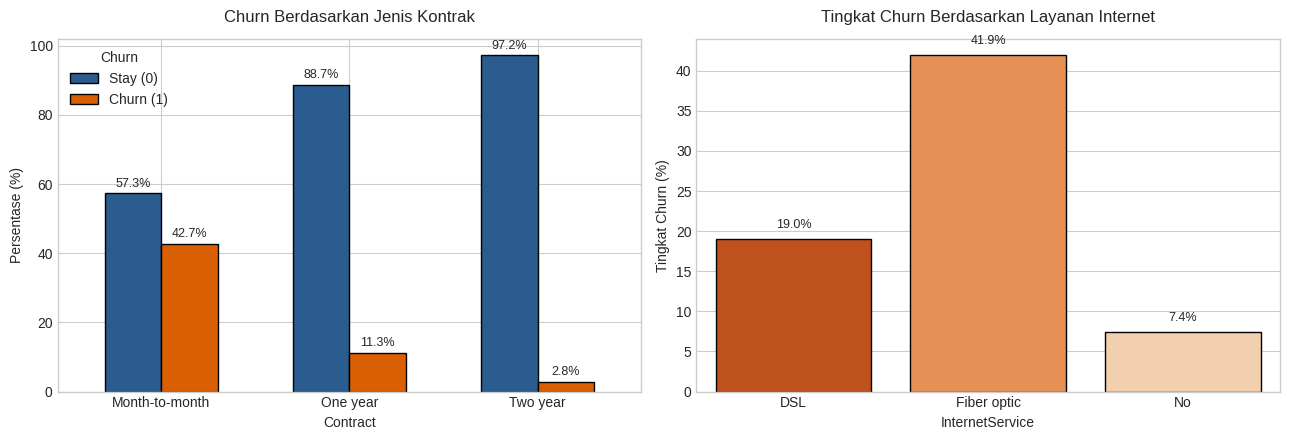

In [4]:
# 2.3 Hubungan Jenis Kontrak & Layanan Internet terhadap Churn
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Grafik 1: Jenis Kontrak
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=False, color=['#2b5c8f', '#d95f02'], ax=axes[0], edgecolor='black', width=0.6)
axes[0].set_title('Churn Berdasarkan Jenis Kontrak', pad=12)
axes[0].set_ylabel('Persentase (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(title='Churn', labels=['Stay (0)', 'Churn (1)'])

# Grafik 2: Layanan Internet
tech_churn = df.groupby(['InternetService'])['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
sns.barplot(x=tech_churn.index, y=tech_churn.values, palette='Oranges_r', ax=axes[1], edgecolor='black')
axes[1].set_title('Tingkat Churn Berdasarkan Layanan Internet', pad=12)
axes[1].set_ylabel('Tingkat Churn (%)')

for ax in axes:
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


**Insight 3:**  
Kontrak bulanan (*Month-to-month*) memiliki churn tertinggi (**42,7%**), dan pengguna *Fiber optic* mencatatkan tingkat churn tertinggi (**41,9%**).


## 3. Data Cleaning
Membereskan temuan anomali pada Bab 2:
- Hapus identifier `customerID`.
- Ubah `TotalCharges` ke numerik dan isi `0.0` pada yang kosong.
- Ubah target `Churn` ke biner (Yes=1, No=0).
- Cek dan pastikan tidak ada baris duplikat.


In [5]:
df_clean = df.copy()

# 1. Hapus kolom ID
df_clean = df_clean.drop(columns=['customerID'], errors='ignore')

# 2. Bersihkan TotalCharges
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'].astype(str).str.strip(), errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)

# 3. Encoding target Churn
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# 4. Hapus duplikat jika ada
df_clean = df_clean.drop_duplicates()

print(f"Data Bersih Siap Pakai: {df_clean.shape[0]:,} baris, {df_clean.shape[1]} kolom (Sisa missing: {df_clean.isnull().sum().sum()})")
df_clean[['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']].head(3)


Data Bersih Siap Pakai: 7,021 baris, 20 kolom (Sisa missing: 0)


,tenure,MonthlyCharges,TotalCharges,Contract,Churn
0,1,29.85,29.85,Month-to-month,0
1,34,56.95,1889.50,One year,0
2,2,53.85,108.15,Month-to-month,1


## 4. Train/Test Split & Machine Learning Pipeline
- Stratified Split (80:20) untuk menjaga rasio churn 73:26.
- `ColumnTransformer`: `StandardScaler` untuk numerik, `OneHotEncoder` untuk kategori.
- Zero Data Leakage: Rumus transformasi hanya dipelajari (*fit*) dari data latih.


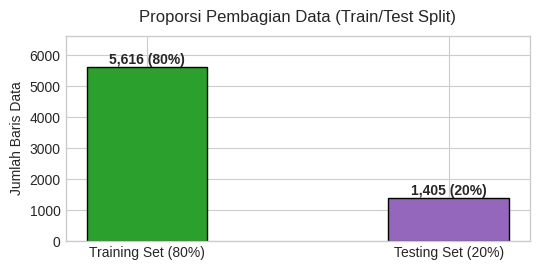

In [6]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

# Stratified Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

fig, ax = plt.subplots(figsize=(5.5, 2.8))
bars = ax.bar(['Training Set (80%)', 'Testing Set (20%)'], [len(X_train), len(X_test)], color=['#2ca02c', '#9467bd'], width=0.4, edgecolor='black')

for bar in bars:
    h = bar.get_height()
    pct = (h / len(X)) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 100, f"{h:,} ({pct:.0f}%)", ha='center', fontweight='bold')

ax.set_title('Proporsi Pembagian Data (Train/Test Split)', pad=10)
ax.set_ylabel('Jumlah Baris Data')
ax.set_ylim(0, len(X_train) * 1.18)
plt.tight_layout()
plt.show()


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features)
])

# Membungkus Preprocessor dan Estimator ke dalam Full Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# Training model
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
print("Pipeline berhasil dilatih tanpa data leakage!")


Pipeline berhasil dilatih tanpa data leakage!


## 5. Model Evaluation
Evaluasi pada data uji (*unseen data*) menggunakan Confusion Matrix dan perbandingan F1-Score per kelas.


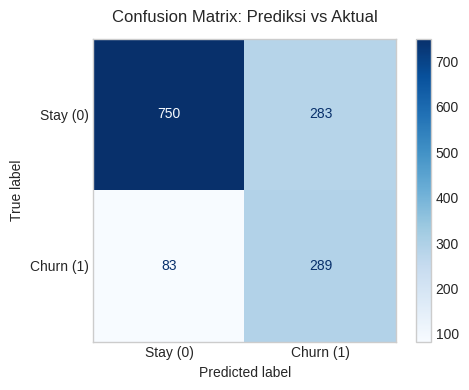

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Stay (0)', 'Churn (1)'],
    cmap='Blues', ax=ax, colorbar=True
)
ax.set_title('Confusion Matrix: Prediksi vs Aktual', pad=12)
ax.grid(False)
plt.tight_layout()
plt.show()


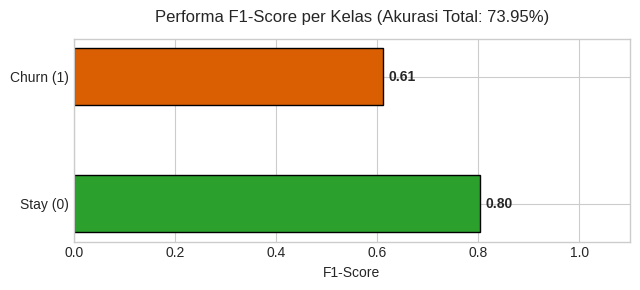

In [9]:
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
categories = ['Stay (0)', 'Churn (1)']
f1_scores = [report_dict['0']['f1-score'], report_dict['1']['f1-score']]

perf_df = pd.DataFrame({'Status': categories, 'F1-Score': f1_scores})

plt.figure(figsize=(6.5, 3))
bars = plt.barh(perf_df['Status'], perf_df['F1-Score'], color=['#2ca02c', '#d95f02'], edgecolor='black', height=0.45)

for bar in bars:
    val = bar.get_width()
    plt.text(val + 0.01, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va='center', fontweight='bold', fontsize=10)

acc = accuracy_score(y_test, y_pred)
plt.title(f'Performa F1-Score per Kelas (Akurasi Total: {acc*100:.2f}%)', pad=12)
plt.xlabel('F1-Score')
plt.xlim(0, 1.1)
plt.tight_layout()
plt.show()
